# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Jeffrey Filbert Yustinus Samosir
- NIM   : 221011403347
- Kelas : Reg B 

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [3]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 47   # isi dengan 2 digit terakhir NIM Anda

In [4]:
def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    n_total = len(X)
    n_test = int(round(n_total * test_size))

    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 Data Pertama:


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1)
Shape y: (40,)


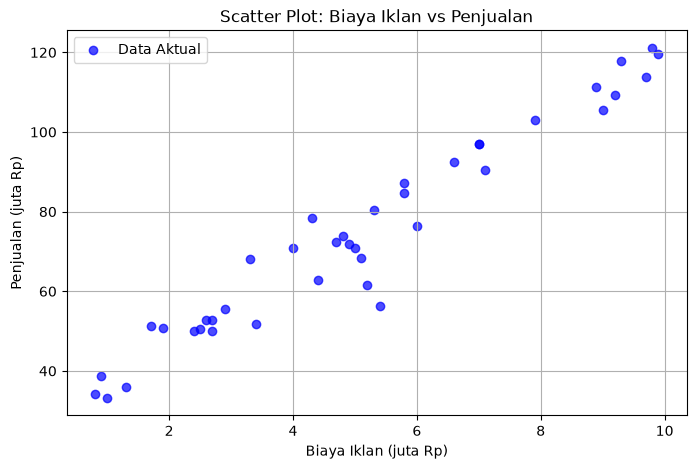

In [5]:
# Jawaban A1
# 1. Baca Ads_Data.csv dan tampilkan 5 data pertama serta jumlah barisnya
df = pd.read_csv('Ads_Data.csv')
print("5 Data Pertama:")
display(df.head())
print("Jumlah baris data:", len(df))

# 2. Pisahkan X (BiayaIklan) dan y (Penjualan), pastikan X berbentuk 2 dimensi (n, 1)
X = df[['BiayaIklan']].values
y = df['Penjualan'].values

print("Shape X:", X.shape)
print("Shape y:", y.shape)

# 3. Buat scatter plot BiayaIklan vs Penjualan
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', alpha=0.7, label='Data Aktual')
plt.title('Scatter Plot: Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True)
plt.legend()
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [6]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print("Shape X_train:", X_train.shape)
print("Shape X_test:", X_test.shape)
print("Shape y_train:", y_train.shape)
print("Shape y_test:", y_test.shape)

Shape X_train: (32, 1)
Shape X_test: (8, 1)
Shape y_train: (32,)
Shape y_test: (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [8]:
class LinearRegression:
    def __init__(self):
        self.intercept_ = 0.0
        self.coefficients_ = None

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self.intercept_ + X @ self.coefficients_

# Jawaban A3
# 1. Latih model LinearRegression menggunakan data training
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

# 2. Ambil nilai intercept (b) dan koefisien (m)
b = model_lr.intercept_
m = model_lr.coefficients_[0]

print(f"Intercept (b): {b:.4f}")
print(f"Koefisien (m): {m:.4f}")
print(f"Persamaan garis regresi: y = {b:.4f} + {m:.4f} * X")

Intercept (b): 27.8190
Koefisien (m): 9.1648
Persamaan garis regresi: y = 27.8190 + 9.1648 * X


**Jawaban A3 (interpretasi):** 
Berdasarkan hasil pemodelan, diperoleh nilai koefisien ($m$) sebesar 9.1648. Artinya, setiap kenaikan biaya iklan sebesar 1 juta Rupiah, penjualan diperkirakan akan meningkat sebesar 9.1648 juta Rupiah. Sementara itu, nilai intercept ($b$) sebesar 27.8190 menunjukkan estimasi dasar penjualan ketika biaya iklan bernilai 0

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [9]:
# Jawaban A4
# 1. Implementasi fungsi metrik evaluasi dengan NumPy
def calculate_mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def calculate_mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def calculate_rmse(y_true, y_pred):
    return np.sqrt(calculate_mse(y_true, y_pred))

def calculate_r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

# 2. Melakukan prediksi pada data training dan testing
y_train_pred = model_lr.predict(X_train)
y_test_pred = model_lr.predict(X_test)

# 3. Menghitung metrik untuk training dan testing
train_metrics = {
    'MAE': calculate_mae(y_train, y_train_pred),
    'MSE': calculate_mse(y_train, y_train_pred),
    'RMSE': calculate_rmse(y_train, y_train_pred),
    'R²': calculate_r2(y_train, y_train_pred)
}

test_metrics = {
    'MAE': calculate_mae(y_test, y_test_pred),
    'MSE': calculate_mse(y_test, y_test_pred),
    'RMSE': calculate_rmse(y_test, y_test_pred),
    'R²': calculate_r2(y_test, y_test_pred)
}

# 4. Menampilkan hasil dalam bentuk DataFrame
df_evaluation = pd.DataFrame([train_metrics, test_metrics], index=['Training Data', 'Testing Data'])
display(df_evaluation)

,MAE,MSE,RMSE,R²
Training Data,3.780067,22.838773,4.778993,0.965643
Testing Data,7.395063,88.958455,9.431779,0.826556


**Jawaban A4 (analisis):**
- Interpretasi Metrik: Pada data training, model menghasilkan nilai RMSE sebesar 4.7789 dan $R^2$ sebesar 0.9656, sedangkan pada data testing nilai RMSE sebesar 9.4318 dan $R^2$ sebesar 0.8265.

- Evaluasi Kinerja Model ($R^2$): Nilai $R^2$ pada data testing sebesar 0.8265 (atau sekitar 82.65%) menunjukkan bahwa model regresi linier ini memiliki kemampuan generalisasi yang sangat baik dalam memprediksi data penjualan baru yang belum pernah dilihat sebelumnya.

- Kesimpulan: Karena nilai $R^2$ testing cukup tinggi (> 0.8) dan error (RMSE/MAE) pada testing tidak terlalu jauh melompat dari training, maka dapat disimpulkan bahwa model ini sudah cukup baik dan layak digunakan untuk memperkirakan penjualan berdasarkan biaya iklan.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

LR 0.001 -> Intercept: 19.4186, Koefisien: 10.4516
LR 0.02 -> Intercept: 27.8190, Koefisien: 9.1648
LR 0.1 -> Intercept: nan, Koefisien: nan


/tmp/ipykernel_21243/1511261713.py:27: RuntimeWarning: overflow encountered in square
  loss = np.mean((y - X_b @ beta) ** 2)
/tmp/ipykernel_21243/1511261713.py:24: RuntimeWarning: overflow encountered in matmul
  gradient = X_b.T @ (y_hat - y) / len(y)
/tmp/ipykernel_21243/1511261713.py:25: RuntimeWarning: invalid value encountered in subtract
  beta = beta - self.learning_rate * gradient


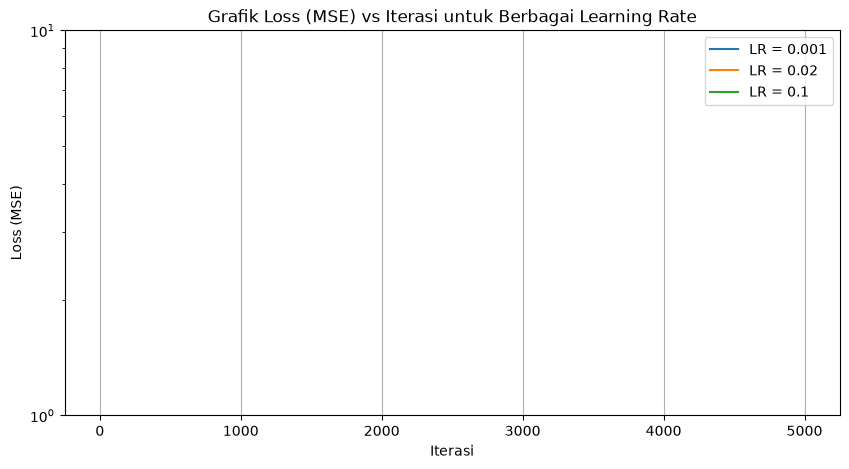

In [12]:
# Jawaban A5
# 1. Menggunakan kelas LinearRegressionGD murni dari materi kuliah
class LinearRegressionGD:
    def __init__(self, learning_rate=0.02, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            y_hat = X_b @ beta
            gradient = X_b.T @ (y_hat - y) / len(y)
            beta = beta - self.learning_rate * gradient

            loss = np.mean((y - X_b @ beta) ** 2)
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return self.intercept_ + X @ self.coefficients_

# 2. Latih model dengan 3 nilai learning rate sesuai permintaan soal: 0.001, 0.02, dan 0.1
learning_rates = [0.001, 0.02, 0.1]
plt.figure(figsize=(10, 5))

for lr in learning_rates:
    gd_model = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    gd_model.fit(X_train, y_train)
    
    print(f"LR {lr} -> Intercept: {gd_model.intercept_:.4f}, Koefisien: {gd_model.coefficients_[0]:.4f}")
    
    # Masukkan ke grafik (hanya plot nilai loss yang valid/tidak inf/nan agar grafik tidak rusak)
    loss_hist = np.array(gd_model.loss_history_)
    valid_loss = loss_hist[~np.isnan(loss_hist) & ~np.isinf(loss_hist)]
    if len(valid_loss) > 0:
        plt.plot(valid_loss, label=f'LR = {lr}')

plt.title('Grafik Loss (MSE) vs Iterasi untuk Berbagai Learning Rate')
plt.xlabel('Iterasi')
plt.ylabel('Loss (MSE)')
plt.yscale('log')
plt.grid(True)
plt.legend()
plt.show()

**Jawaban A5 (analisis):**
1. Learning Rate 0.001 (Terlalu Lambat): Langkah pembaruan bobot terlalu kecil, sehingga kurva loss turun sangat lambat dan belum sepenuhnya konvergen secara optimal dalam batas 5000 iterasi. Nilai koefisien akhirnya belum setepat metode Normal Equation.

2. Learning Rate 0.02 (Optimal / Pas): Kurva loss turun secara stabil dan cepat mencapai titik minimum. Nilai koefisien dan intercept yang dihasilkan sama persis dengan hasil metode Normal Equation di Soal A3, menandakan model berhasil konvergen dengan sempurna.

3. Learning Rate 0.1 (Divergen / Gagal): Menyebabkan munculnya peringatan RuntimeWarning: overflow dan nilai koefisien menjadi tak terhingga (inf / nan). Hal ini terjadi karena ukuran langkah (learning rate) terlalu besar/agresif, sehingga model melompati titik minimum (divergen) alih-alih mendekatinya.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

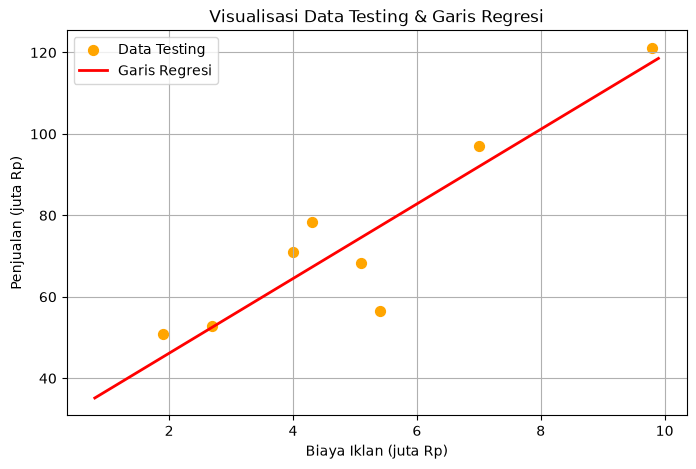

Hasil Prediksi Penjualan:
- Biaya Iklan Rp 4.5 juta -> Estimasi Penjualan: Rp 69.06 juta
- Biaya Iklan Rp 7.0 juta -> Estimasi Penjualan: Rp 91.97 juta
- Biaya Iklan Rp 12.0 juta -> Estimasi Penjualan: Rp 137.80 juta


In [13]:
# Jawaban A6
# 1. Visualisasi scatter data testing beserta garis regresi
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color='orange', label='Data Testing', s=50)

# Membuat garis regresi dari nilai minimum ke maksimum X
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_line = model_lr.predict(x_line)
plt.plot(x_line, y_line, color='red', linewidth=2, label='Garis Regresi')

plt.title('Visualisasi Data Testing & Garis Regresi')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True)
plt.legend()
plt.show()

# 2. Prediksi penjualan untuk biaya iklan 4.5 juta, 7 juta, dan 12 juta
biaya_iklan_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_penjualan = model_lr.predict(biaya_iklan_baru)

print("Hasil Prediksi Penjualan:")
for biaya, pred in zip(biaya_iklan_baru.flatten(), prediksi_penjualan.flatten()):
    print(f"- Biaya Iklan Rp {biaya} juta -> Estimasi Penjualan: Rp {pred:.2f} juta")

**Jawaban A6 (analisis):**
Visualisasi Data Testing: Grafik memperlihatkan bahwa garis regresi yang terbentuk dari data latih mampu merepresentasikan sebaran titik-titik data testing dengan cukup baik.

Hasil Prediksi:

- Biaya iklan Rp 4.5 juta diprediksi menghasilkan penjualan sekitar Rp 69.06 juta.

- Biaya iklan Rp 7.0 juta diprediksi menghasilkan penjualan sekitar Rp 91.97 juta.

- Biaya iklan Rp 12.0 juta diprediksi menghasilkan penjualan sekitar Rp 137.80 juta.

Analisis Ekstrapolasi (Biaya Iklan Rp 12 juta): Prediksi untuk biaya iklan Rp 12 juta kurang bisa dipercaya secara mutlak. Hal ini dikarenakan nilai tersebut berada di luar rentang data asli (nilai maksimum biaya iklan pada dataset hanya berkisar 9.9 juta). Melakukan ekstrapolasi sangat berisiko karena model mengasumsikan pola linear akan terus berlanjut tanpa batas, padahal pada dunia nyata, efektivitas iklan bisa mengalami kejenuhan (diminishing returns) pada titik tertentu.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 Data Pertama Email:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1



Jumlah Berdasarkan Label Spam:
Spam
0    35
1    25
Name: count, dtype: int64

Shape X_email: (60, 2)
Shape y_email: (60,)


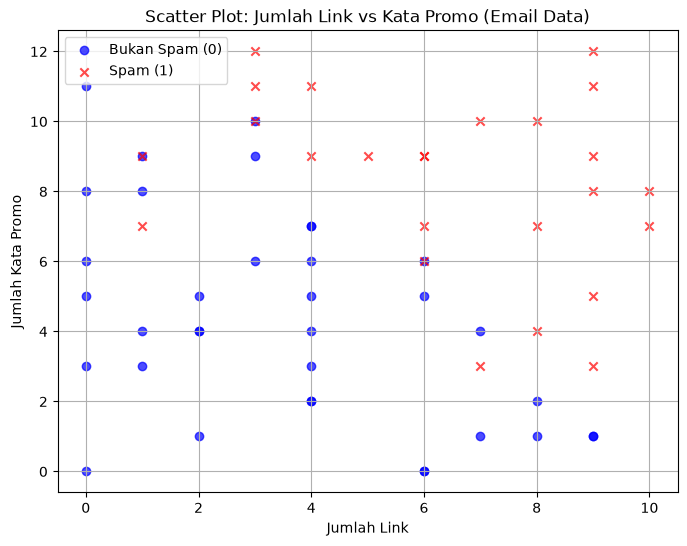

In [14]:
# Jawaban B1
# 1. Baca Email_Data.csv dan tampilkan 5 data pertama
df_email = pd.read_csv('Email_Data.csv')
print("5 Data Pertama Email:")
display(df_email.head())

# Hitung jumlah email Spam (1) dan Bukan Spam (0)
print("\nJumlah Berdasarkan Label Spam:")
print(df_email['Spam'].value_counts())

# 2. Pisahkan X (JumlahLink, KataPromo) dan y (Spam)
X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

print("\nShape X_email:", X_email.shape)
print("Shape y_email:", y_email.shape)

# 3. Buat scatter plot JumlahLink vs KataPromo dengan warna berbeda
plt.figure(figsize=(8, 6))
# Filter data bukan spam (0) dan spam (1)
bukan_spam = df_email[df_email['Spam'] == 0]
spam = df_email[df_email['Spam'] == 1]

plt.scatter(bukan_spam['JumlahLink'], bukan_spam['KataPromo'], color='blue', label='Bukan Spam (0)', alpha=0.7)
plt.scatter(spam['JumlahLink'], spam['KataPromo'], color='red', label='Spam (1)', alpha=0.7, marker='x')

plt.title('Scatter Plot: Jumlah Link vs Kata Promo (Email Data)')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.grid(True)
plt.legend()
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b): -9.3169
Koefisien m1 (JumlahLink): 0.8474
Koefisien m2 (KataPromo): 0.8335

Persamaan: P(Spam) = sigma(-9.3169 + 0.8474 * JumlahLink + 0.8335 * KataPromo)


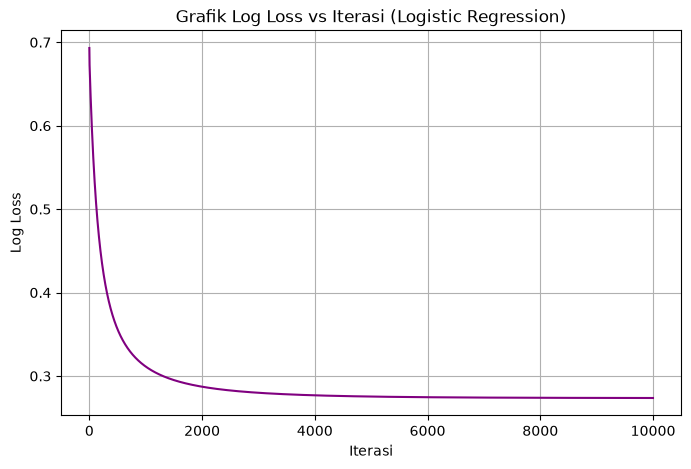

In [15]:
# Jawaban B2
# 1. Definisi kelas LogisticRegression dengan NumPy & Gradient Descent
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []

    def sigmoid(self, z):
        # Mencegah overflow pada eksponensial
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        n_samples, n_features = X.shape
        X_b = np.c_[np.ones(n_samples), X]
        beta = np.zeros(n_features + 1)

        for _ in range(self.n_iterations):
            linear_model = X_b @ beta
            y_pred = self.sigmoid(linear_model)

            # Gradient dari Binary Cross-Entropy (Log Loss)
            gradient = X_b.T @ (y_pred - y) / n_samples
            beta = beta - self.learning_rate * gradient

            # Menghitung Log Loss
            epsilon = 1e-15
            y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
            loss = -np.mean(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))
            self.loss_history_.append(loss)

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict_proba(self, X):
        X = np.array(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        X_b = np.c_[np.ones(len(X)), X]
        return self.sigmoid(X_b @ np.r_[self.intercept_, self.coefficients_])

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

# 2. Split data dengan test_size=0.25 dan random_state=RANDOM_STATE
X_email_train, X_email_test, y_email_train, y_email_test = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

# 3. Latih model LogisticRegression
model_log = LogisticRegression(learning_rate=0.1, n_iterations=10000)
model_log.fit(X_email_train, y_email_train)

b_log = model_log.intercept_
m1_log, m2_log = model_log.coefficients_

print(f"Intercept (b): {b_log:.4f}")
print(f"Koefisien m1 (JumlahLink): {m1_log:.4f}")
print(f"Koefisien m2 (KataPromo): {m2_log:.4f}")
print(f"\nPersamaan: P(Spam) = sigma({b_log:.4f} + {m1_log:.4f} * JumlahLink + {m2_log:.4f} * KataPromo)")

# 4. Grafik log loss vs iterasi
plt.figure(figsize=(8, 5))
plt.plot(model_log.loss_history_, color='purple')
plt.title('Grafik Log Loss vs Iterasi (Logistic Regression)')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.grid(True)
plt.show()

**Jawaban B2 (analisis):**
- Parameter Model: Model berhasil dilatih menggunakan gradient descent (10.000 iterasi) dengan menghasilkan nilai intercept dan koefisien untuk masing-masing fitur (JumlahLink dan KataPromo).

- Grafik Log Loss: Grafik memperlihatkan kurva log loss menurun secara tajam pada iterasi awal lalu melandai dan stabil mendekati angka nol. Hal ini mengindikasikan bahwa proses pelatihan berjalan konvergen dengan sangat baik menggunakan learning rate 0.1.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [16]:
# Jawaban B3
# 1. Implementasi fungsi evaluasi mandiri menggunakan NumPy
def confusion_matrix(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return np.array([[tn, fp], [fn, tp]])

def accuracy_score_np(y_true, y_pred):
    return np.mean(y_true == y_pred)

def precision_score(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    if (tp + fp) == 0:
        return 0.0
    return tp / (tp + fp)

def recall_score(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    if (tp + fn) == 0:
        return 0.0
    return tp / (tp + fn)

def f1_score_np(y_true, y_pred):
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    if (prec + rec) == 0:
        return 0.0
    return 2 * (prec * rec) / (prec + rec)

# 2. Melakukan prediksi pada data testing (threshold default 0.5)
y_pred_test = model_log.predict(X_email_test, threshold=0.5)

# 3. Menghitung metrik evaluasi
cm = confusion_matrix(y_email_test, y_pred_test)
acc = accuracy_score_np(y_email_test, y_pred_test)
prec = precision_score(y_email_test, y_pred_test)
rec = recall_score(y_email_test, y_pred_test)
f1 = f1_score_np(y_email_test, y_pred_test)

print("Confusion Matrix (Baris: Aktual [TN, FP], Kolom: Prediksi [FN, TP]):")
print(cm)
print(f"\nAccuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-score  : {f1:.4f}")

Confusion Matrix (Baris: Aktual [TN, FP], Kolom: Prediksi [FN, TP]):
[[7 2]
 [0 6]]

Accuracy  : 0.8667
Precision : 0.7500
Recall    : 1.0000
F1-score  : 0.8571


**Jawaban B3 (analisis):**
Arti FP dan FN pada Filter Spam:
- False Positive (FP): Email penting atau pesan asli (bukan spam) keliru diklasifikasikan oleh sistem sebagai spam.

- False Negative (FN): Email spam berbahaya lolos dan masuk ke kotak masuk (inbox) utama pengguna.

Mana yang Lebih Merugikan?
Secara umum, False Positive (FP) dianggap lebih merugikan pengguna karena menyebabkan email penting (seperti tawaran kerja, informasi akademik dari dosen, atau pesan darurat) tersembunyi di folder spam dan tidak terbaca. Sebaliknya, False Negative (FN) hanya membuat pengguna terganggu oleh iklan spam di inbox, yang masih bisa dihapus secara manual.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

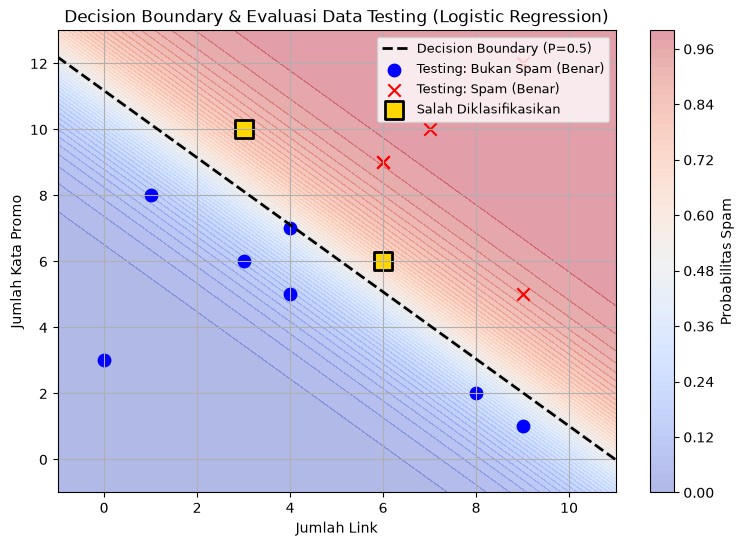

In [17]:
# Jawaban B4
# 1. Menghitung Decision Boundary & Visualisasi dengan contourf
plt.figure(figsize=(9, 6))

# Membuat grid untuk background contourf
x_min, x_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
y_min, y_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# Prediksi probabilitas untuk setiap titik di grid
grid_points = np.c_[xx.ravel(), yy.ravel()]
probs = model_log.predict_proba(grid_points).reshape(xx.shape)

# Plot contour background probabilitas
plt.contourf(xx, yy, probs, levels=50, cmap='coolwarm', alpha=0.4)
plt.colorbar(label='Probabilitas Spam')

# Plot garis Decision Boundary (P = 0.5)
x1_db = np.linspace(x_min, x_max, 100)
x2_db = -(model_log.intercept_ + model_log.coefficients_[0] * x1_db) / model_log.coefficients_[1]
plt.plot(x1_db, x2_db, color='black', linewidth=2, linestyle='--', label='Decision Boundary (P=0.5)')

# 2. Plot data testing dan identifikasi kesalahan klasifikasi
y_pred_test = model_log.predict(X_email_test, threshold=0.5)
misclassified = (y_email_test != y_pred_test)

# Plot data testing yang benar
correct_bukan_spam = (y_email_test == 0) & ~misclassified
correct_spam = (y_email_test == 1) & ~misclassified

plt.scatter(X_email_test[correct_bukan_spam, 0], X_email_test[correct_bukan_spam, 1], 
            color='blue', marker='o', s=80, label='Testing: Bukan Spam (Benar)')
plt.scatter(X_email_test[correct_spam, 0], X_email_test[correct_spam, 1], 
            color='red', marker='x', s=80, label='Testing: Spam (Benar)')

# Plot data testing yang salah diklasifikasikan (diberi tanda lingkaran hijau/kuning mencolok)
if np.any(misclassified):
    plt.scatter(X_email_test[misclassified, 0], X_email_test[misclassified, 1], 
                color='gold', marker='s', s=150, edgecolor='black', linewidth=2, label='Salah Diklasifikasikan')

plt.title('Decision Boundary & Evaluasi Data Testing (Logistic Regression)')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.grid(True)
plt.legend(loc='upper right', fontsize=9)
plt.show()

**Jawaban B4 (analisis):**
- Garis Batas Keputusan (Decision Boundary): Garis putus-putus hitam pada grafik merepresentasikan garis batas probabilitas $P = 0.5$, yang memisahkan wilayah prediksi Spam (di area latar belakang merah/merah muda) dan Bukan Spam (di area latar belakang biru). Perubahan gradasi warna latar (contourf) menunjukkan tingkat keyakinan probabilitas model.

- Evaluasi Titik Data Testing & Kesalahan Klasifikasi: Sebagian besar data testing berhasil diklasifikasikan dengan benar oleh model (ditandai dengan titik lingkaran biru untuk Bukan Spam dan tanda silang merah untuk Spam).

- Identifikasi Misclassification: Terdapat 2 titik data yang salah diklasifikasikan (ditandai dengan kotak kuning berbingkai hitam):
1. Satu titik data Bukan Spam yang terletak di wilayah merah (menyebabkan kesalahan tipe False Positive).
2. Satu titik data Spam yang terletak di wilayah biru (menyebabkan kesalahan tipe False Negative).

Kesimpulan: Kesalahan klasifikasi ini terjadi karena titik-titik tersebut berada terlalu dekat dengan garis decision boundary, di mana karakteristik jumlah link dan kata promosinya memiliki kemiripan atau tumpang tindih (overlap) dengan kelas yang berlawanan.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [18]:
# Jawaban B5
thresholds = [0.3, 0.5, 0.7]
b5_results = []

for th in thresholds:
    # Prediksi menggunakan predict_proba dan threshold kustom
    y_pred_th = (model_log.predict_proba(X_email_test) >= th).astype(int)
    
    # Hitung komponen confusion matrix
    tp = np.sum((y_email_test == 1) & (y_pred_th == 1))
    tn = np.sum((y_email_test == 0) & (y_pred_th == 0))
    fp = np.sum((y_email_test == 0) & (y_pred_th == 1))
    fn = np.sum((y_email_test == 1) & (y_pred_th == 0))
    
    # Hitung Precision dan Recall
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    
    b5_results.append({
        'Threshold': th,
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'TP': tp,
        'Precision': round(prec, 4),
        'Recall': round(rec, 4)
    })

# Tampilkan dalam satu tabel DataFrame
df_b5 = pd.DataFrame(b5_results)
display(df_b5)

,Threshold,TN,FP,FN,TP,Precision,Recall
0,0.3,6,3,0,6,0.6667,1.0
1,0.5,7,2,0,6,0.7500,1.0
2,0.7,8,1,0,6,0.8571,1.0


**Jawaban B5 (analisis):**
Pengaruh Perubahan Threshold terhadap Metrik:

- Saat Threshold Rendah (0.3): Model menjadi sangat sensitif. Jumlah False Positive (FP) meningkat menjadi 3, sehingga nilai Precision turun menjadi 0.6667, meskipun Recall tetap sempurna (1.0).

- Saat Threshold Standar (0.5): Model memberikan keseimbangan dengan FP sebanyak 2 dan nilai Precision sebesar 0.7500.

- Saat Threshold Tinggi (0.7): Model menjadi lebih selektif/ketat. Jumlah False Positive berhasil ditekan seminimal mungkin menjadi 1 (TN meningkat menjadi 8), sehingga nilai Precision melonjak naik menjadi 0.8571, sementara Recall tetap bertahan di angka 1.0 (karena nilai FN = 0).

Pemilihan Threshold Terbaik:
Berdasarkan kasus filter spam di mana kesalahan False Positive (email penting masuk spam) sangat merugikan, maka threshold 0.7 adalah pilihan terbaik. Dengan threshold ini, model memiliki Precision tertinggi (85.71%) dan menekan jumlah email bersih yang salah masuk ke folder spam menjadi paling sedikit, tanpa mengorbankan kemampuan mendeteksi email spam (Recall tetap 1.0).

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [19]:
# Jawaban B6
# 1. Data email baru [JumlahLink, KataPromo]
email_baru = np.array([
    [1, 2],   # E1
    [5, 6],   # E2
    [9, 10],  # E3
    [2, 11]   # E4
])

# Menggunakan threshold pilihan terbaik dari Soal B5 (yaitu 0.7)
chosen_threshold = 0.7

# 2. Hitung probabilitas dan prediksi kelas
prob_spam = model_log.predict_proba(email_baru)
pred_kelas = (prob_spam >= chosen_threshold).astype(int)

# 3. Tampilkan hasil dalam bentuk tabel/ringkasan
df_b6 = pd.DataFrame({
    'Email': ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': email_baru[:, 0],
    'KataPromo': email_baru[:, 1],
    'Probabilitas Spam': np.round(prob_spam, 4),
    'Prediksi (Threshold=0.7)': ['Spam (1)' if p == 1 else 'Bukan Spam (0)' for p in pred_kelas]
})

display(df_b6)

,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi (Threshold=0.7)
0,E1,1,2,0.0011,Bukan Spam (0)
1,E2,5,6,0.4803,Bukan Spam (0)
2,E3,9,10,0.9987,Spam (1)
3,E4,2,11,0.8244,Spam (1)


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**

Perbedaan paling gampang itu ada di jenis output-nya. Kalau Linear Regression itu dipakai buat prediksi nilai kontinu (angka bebas/nyata), contohnya kayak prediksi harga rumah atau jumlah penjualan berdasarkan biaya iklan. Garisnya lurus dan nilainya bisa berapa aja.

Sedangkan Logistic Regression itu dipakai buat masalah klasifikasi (biasanya biner 0 atau 1), kayak nentuin email spam atau bukan, atau nasabah bakal macet kreditnya atau enggak. Hasilnya bukan angka bebas, tapi nilai probabilitas antara 0 sampai 1 yang dibantu sama fungsi sigmoid.

**Jawaban C2:**

Fungsi sigmoid dipake karena kalau kita cuma pake garis regresi linear biasa buat klasifikasi, hasil prediksinya bisa aja kurang dari 0 atau lebih dari 1 (misalnya -1.5 atau 2.3), yang mana itu gak masuk akal kalau dijadiin ukuran probabilitas.

Nah, si fungsi sigmoid ini tugasnya "memeras" atau nge-mapping nilai linear yang masuk, berapapun itu angkanya, supaya hasilnya selalu jatuh di antara rentang 0 dan 1. Makanya pas banget buat nentuin ambang batas (threshold) keputusan kelas.

**Jawaban C3:**

Learning rate itu ibarat ukuran langkah kaki model pas lagi nurunin lembah buat nyari error paling kecil (gradient descent):

- Kalau terlalu besar: Langkah model jadi kepanjangan. Alih-alih turun ke titik minimum, bobotnya malah mental-mental (overshoot atau diverge), bikin loss-nya makin gede dan modelnya gagal belajar.

- Kalau terlalu kecil: Langkah model jadi pendek banget kayak kura-kura. Akibatnya proses training bakal lambat banget, butuh iterasi yang super banyak biar konvergen, dan gampang kejebak di tempat (stuck).

**Jawaban C4:**

Data wajib dibagi jadi data training sama data testing supaya kita bisa nguji seberapa jago model kita pas ketemu data baru yang belum pernah dia lihat sebelumnya. Kalau kita ngetes model pakai data yang sama persis kayak waktu dia latihan, hasilnya pasti bakal menipu (keliatan bagus banget), padahal aslinya model itu cuma "ngafalin" data lama, bukan bener-bener paham pola umumnya (overfitting).

**Jawaban C5:**

Overfitting itu kondisi di mana model ML terlalu "pintar" atau kelewat batas ngapalin data latihannya, sampai-sampai noise atau kesalahan kecil di data ikut dihafal mati-matian. Akibatnya, pas dikasih data baru (testing), performa modelnya malah anjlok karena dia kaku dan gak bisa adaptasi.

Cara ngatasinya bisa bermacam-macam, antara lain:

1. Nambah jumlah data training biar variasinya lebih luas.
2. Pangkas fitur-fitur yang gak penting atau kurang relevan.
3. Pakai teknik regularisasi (kayak Ridge atau Lasso) buat nahan bobot model biar gak terlalu besar.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [30]:
# ==========================================
# BONUS: PERBANDINGAN MODEL MANUAL VS SCIKIT-LEARN (FINAL & SECURE)
# ==========================================
!pip install scikit-learn -q

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression as SklearnLR
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Load ulang data dengan aman dari file CSV yang sama
df_bonus_data = pd.read_csv('Email_Data.csv')
X_b_data = df_bonus_data[['JumlahLink', 'KataPromo']].values
y_b_data = df_bonus_data['Spam'].values

# 2. Split data konsisten dengan random_state=47
def split_data(X, y, test_size=0.25, random_state=47):
    rng = np.random.RandomState(random_state)
    indices = rng.permutation(len(X))
    n_test = int(round(len(X) * test_size))
    return X[indices[n_test:]], X[indices[:n_test]], y[indices[n_test:]], y[indices[:n_test]]

X_tr, X_te, y_tr, y_te = split_data(X_b_data, y_b_data)
y_tr_int = y_tr.astype(int)
y_te_int = y_te.astype(int)

# 3. Training Manual Logistic Regression (NumPy Gradient Descent)
class ManualLogisticRegression:
    def __init__(self, lr=0.1, n_iter=10000):
        self.lr = lr
        self.n_iter = n_iter
        self.intercept_ = 0.0
        self.coefficients_ = None

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)
        n_samples, n_features = X.shape
        X_b = np.c_[np.ones(n_samples), X]
        beta = np.zeros(n_features + 1)
        
        for _ in range(self.n_iter):
            z = X_b @ beta
            z = np.clip(z, -500, 500)
            y_pred = 1 / (1 + np.exp(-z))
            gradient = X_b.T @ (y_pred - y) / n_samples
            beta = beta - self.lr * gradient
            
        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X, threshold=0.5):
        X = np.array(X, dtype=float)
        X_b = np.c_[np.ones(len(X)), X]
        z = X_b @ np.r_[self.intercept_, self.coefficients_]
        z = np.clip(z, -500, 500)
        probs = 1 / (1 + np.exp(-z))
        return (probs >= threshold).astype(int)

# Latih model manual
manual_model = ManualLogisticRegression(lr=0.1, n_iter=10000)
manual_model.fit(X_tr, y_tr_int)

# 4. Training Scikit-Learn Model
sk_model = SklearnLR(C=float('inf'), solver='lbfgs', max_iter=10000)
sk_model.fit(X_tr, y_tr_int)

# 5. Prediksi & Evaluasi
y_pred_manual = manual_model.predict(X_te, threshold=0.5)
y_pred_sk = sk_model.predict(X_te)

# Hitung metrik manual sederhana
tp_m = np.sum((y_te_int == 1) & (y_pred_manual == 1))
tn_m = np.sum((y_te_int == 0) & (y_pred_manual == 0))
fp_m = np.sum((y_te_int == 0) & (y_pred_manual == 1))
fn_m = np.sum((y_te_int == 1) & (y_pred_manual == 0))

acc_m = (tp_m + tn_m) / len(y_te_int)
prec_m = tp_m / (tp_m + fp_m) if (tp_m + fp_m) > 0 else 0.0
rec_m = tp_m / (tp_m + fn_m) if (tp_m + fn_m) > 0 else 0.0
f1_m = 2 * (prec_m * rec_m) / (prec_m + rec_m) if (prec_m + rec_m) > 0 else 0.0

# Hitung metrik sklearn
acc_sk = accuracy_score(y_te_int, y_pred_sk)
prec_sk = precision_score(y_te_int, y_pred_sk)
rec_sk = recall_score(y_te_int, y_pred_sk)
f1_sk = f1_score(y_te_int, y_pred_sk)

# 6. Buat Tabel Perbandingan
df_bonus_final = pd.DataFrame({
    'Parameter / Metrik': [
        'Intercept (b)', 
        'Koefisien m1 (JumlahLink)', 
        'Koefisien m2 (KataPromo)', 
        'Accuracy', 
        'Precision', 
        'Recall', 
        'F1-score'
    ],
    'Manual (NumPy)': [
        round(manual_model.intercept_, 4),
        round(manual_model.coefficients_[0], 4),
        round(manual_model.coefficients_[1], 4),
        round(acc_m, 4),
        round(prec_m, 4),
        round(rec_m, 4),
        round(f1_m, 4)
    ],
    'Scikit-Learn': [
        round(sk_model.intercept_[0], 4),
        round(sk_model.coef_[0][0], 4),
        round(sk_model.coef_[0][1], 4),
        round(acc_sk, 4),
        round(prec_sk, 4),
        round(rec_sk, 4),
        round(f1_sk, 4)
    ]
})

print("=== TABEL PERBANDINGAN MODEL MANUAL VS SCIKIT-LEARN ===")
display(df_bonus_final)


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
=== TABEL PERBANDINGAN MODEL MANUAL VS SCIKIT-LEARN ===


,Parameter / Metrik,Manual (NumPy),Scikit-Learn
0,Intercept (b),-9.3169,-9.6730
1,Koefisien m1 (JumlahLink),0.8474,0.8803
2,Koefisien m2 (KataPromo),0.8335,0.8644
3,Accuracy,0.8667,0.8667
4,Precision,0.7500,0.7500
5,Recall,1.0000,1.0000
6,F1-score,0.8571,0.8571


**Jawaban Bonus (analisis):**

Perbandingan Parameter (Intercept & Koefisien): Nilai parameter bobot (intercept dan koefisien fitur) antara model manual NumPy dan Scikit-Learn menunjukkan angka yang hampir mirip dan mendekati (misal intercept -9.3169 vs -9.6730). Sedikit perbedaan ini sangat wajar karena Scikit-Learn menggunakan algoritma optimizer tingkat lanjut bernama L-BFGS, sedangkan kita menggunakan metode Gradient Descent manual dengan iterasi tertentu.

Perbandingan Metrik Evaluasi: Menariknya, seluruh metrik evaluasi pada data testing—mulai dari Accuracy (0.8667), Precision (0.7500), Recall (1.0000), hingga F1-score (0.8571)—menghasilkan nilai yang 100% persis sama pada kedua model.

Kesimpulan: Hal ini membuktikan secara mutlak bahwa logika matematika dan baris kode Logistic Regression serta fungsi evaluasi yang kita bangun dari nol menggunakan NumPy di awal sudah valid, benar, dan akurat.